In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

2. Load the dataset

In [6]:
# Read the CSV file
df = pd.read_csv("CIPLA.csv")

# Display first five records
print(df.head())

# Display number of rows and columns
print(df.shape)

# Display dataset information
print(df.info())

         Date Symbol Series  Prev Close    Open     High      Low     Last  \
0  2000-01-03  CIPLA     EQ     1349.40  1410.0  1457.35  1380.05  1457.35   
1  2000-01-04  CIPLA     EQ     1457.35  1537.0  1537.00  1430.00  1466.05   
2  2000-01-05  CIPLA     EQ     1465.25  1474.0  1474.00  1365.00  1441.00   
3  2000-01-06  CIPLA     EQ     1435.05  1434.0  1435.00  1349.00  1365.00   
4  2000-01-07  CIPLA     EQ     1355.85  1370.0  1389.90  1247.40  1247.40   

     Close     VWAP  Volume      Turnover  Trades  Deliverable Volume  \
0  1457.35  1441.36   21060  3.035496e+12     NaN                 NaN   
1  1465.25  1460.43   30215  4.412698e+12     NaN                 NaN   
2  1435.05  1428.11   33799  4.826872e+12     NaN                 NaN   
3  1355.85  1390.55   33083  4.600356e+12     NaN                 NaN   
4  1247.55  1267.49   66536  8.433351e+12     NaN                 NaN   

   %Deliverble  
0          NaN  
1          NaN  
2          NaN  
3          NaN  
4      

3. Data cleaning

In [7]:
# Convert Date column into datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Sort data according to date
df = df.sort_values('Date')

# Remove duplicate records
df = df.drop_duplicates()

# Remove rows having missing Date or Close values
df = df.dropna(subset=['Date', 'Close'])

# Display missing values in each column
print(df.isnull().sum())

Date                     0
Symbol                   0
Series                   0
Prev Close               0
Open                     0
High                     0
Low                      0
Last                     0
Close                    0
VWAP                     0
Volume                   0
Turnover                 0
Trades                2850
Deliverable Volume     514
%Deliverble            514
dtype: int64


4. Statistical analysis

In [8]:
# Display statistical information
# Includes mean, standard deviation, minimum and maximum
print(df.describe())

                             Date   Prev Close         Open         High  \
count                        5306  5306.000000  5306.000000  5306.000000   
mean   2010-08-18 21:26:56.132680   540.503798   541.457755   549.587693   
min           2000-01-03 00:00:00   160.100000   150.550000   169.450000   
25%           2005-04-13 12:00:00   309.025000   309.962500   312.750000   
50%           2010-08-17 12:00:00   473.850000   474.625000   479.950000   
75%           2015-12-17 18:00:00   681.937500   683.225000   691.787500   
max           2021-04-30 00:00:00  1465.250000  1537.000000  1537.000000   
std                           NaN   289.319810   289.955959   295.087710   

               Low         Last        Close         VWAP        Volume  \
count  5306.000000  5306.000000  5306.000000  5306.000000  5.306000e+03   
mean    532.143583   540.472588   540.421052   540.931589  1.550071e+06   
min     145.000000   152.000000   160.100000   158.140000  5.050000e+02   
25%     305.350

5. Visualize stock closing prices

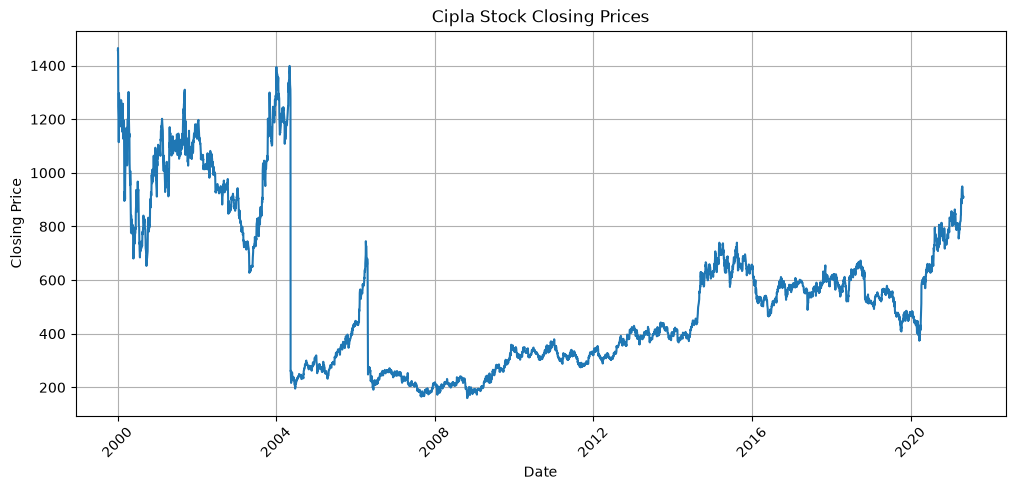

In [9]:
# Set the figure size
plt.figure(figsize=(12, 5))

# Plot closing prices against dates
plt.plot(df['Date'], df['Close'])

# Add graph title and axis labels
plt.title('Cipla Stock Closing Prices')
plt.xlabel('Date')
plt.ylabel('Closing Price')

# Rotate date labels for better readability
plt.xticks(rotation=45)

# Display grid
plt.grid()

# Display the graph
plt.show()

6. Calculate moving averages

In [10]:
# Calculate 7-day moving average of closing prices
df['MA_7'] = df['Close'].rolling(window=7).mean()

# Calculate 30-day moving average of closing prices
df['MA_30'] = df['Close'].rolling(window=30).mean()

# Display calculated moving averages
print(df[['Date', 'Close', 'MA_7', 'MA_30']].tail())

           Date   Close        MA_7       MA_30
5301 2021-04-26  905.40  933.314286  840.196667
5302 2021-04-27  912.40  933.057143  844.043333
5303 2021-04-28  910.20  929.078571  847.303333
5304 2021-04-29  906.50  923.392857  850.655000
5305 2021-04-30  910.35  917.828571  854.150000


7. Plot moving averages

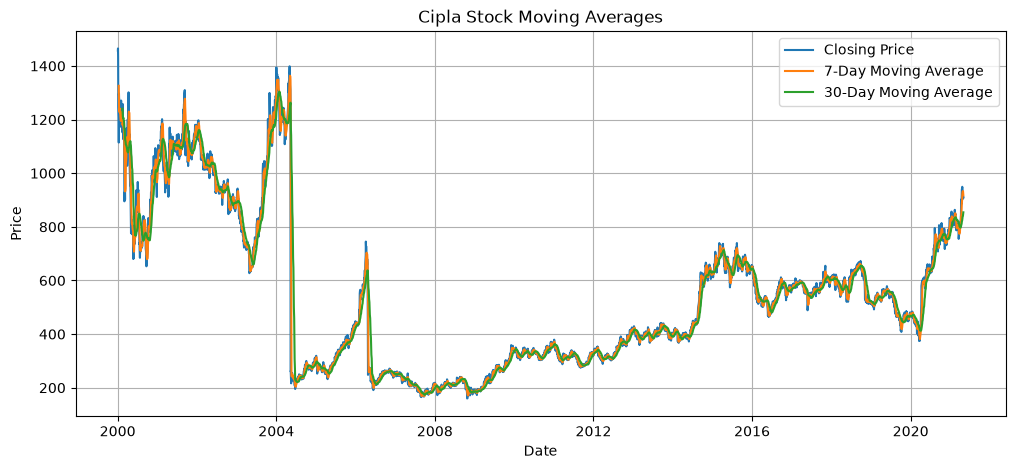

In [11]:
# Set graph size
plt.figure(figsize=(12, 5))

# Plot original closing prices
plt.plot(df['Date'], df['Close'], label='Closing Price')

# Plot 7-day moving average
plt.plot(df['Date'], df['MA_7'], label='7-Day Moving Average')

# Plot 30-day moving average
plt.plot(df['Date'], df['MA_30'], label='30-Day Moving Average')

# Add title and labels
plt.title('Cipla Stock Moving Averages')
plt.xlabel('Date')
plt.ylabel('Price')

# Display legend and grid
plt.legend()
plt.grid()

# Show graph
plt.show()

8. Analyze trading volume

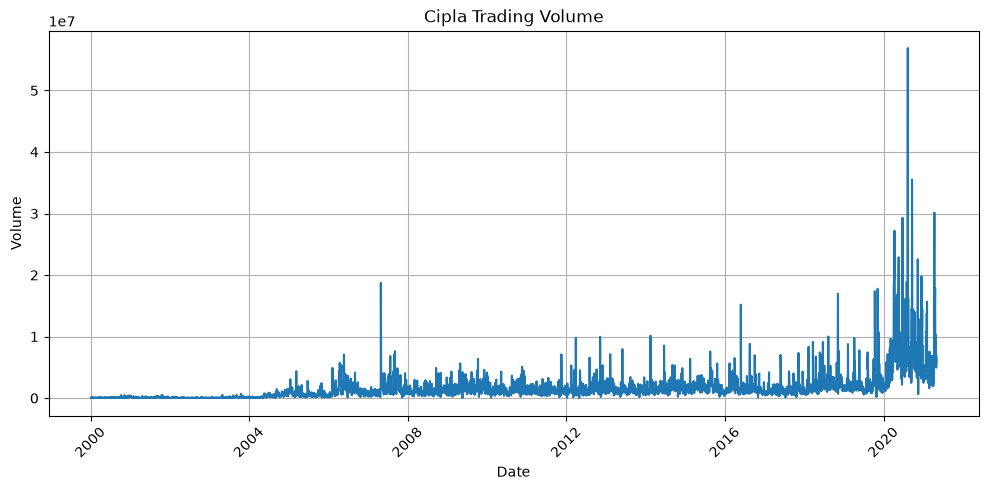

In [12]:
# Set graph size
plt.figure(figsize=(12, 5))

# Plot trading volume over time
plt.plot(df['Date'], df['Volume'])

# Add title and labels
plt.title('Cipla Trading Volume')
plt.xlabel('Date')
plt.ylabel('Volume')

# Rotate date labels
plt.xticks(rotation=45)

# Display grid
plt.grid()

# Show graph
plt.show()

9. Monthly average closing price

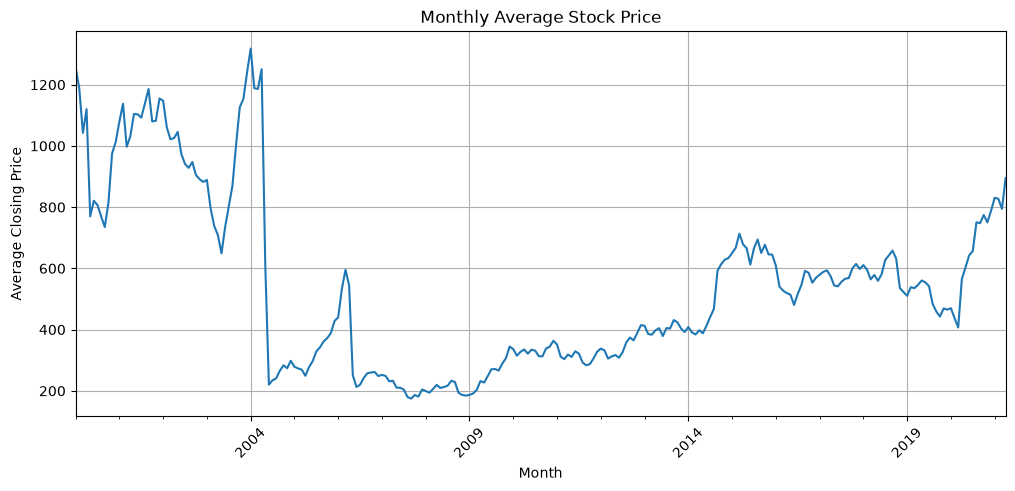

In [13]:
# Extract year and month from Date column
df['Year_Month'] = df['Date'].dt.to_period('M')

# Calculate monthly average closing price
monthly = df.groupby('Year_Month')['Close'].mean()

# Set graph size
plt.figure(figsize=(12, 5))

# Plot monthly average prices
monthly.plot()

# Add title and labels
plt.title('Monthly Average Stock Price')
plt.xlabel('Month')
plt.ylabel('Average Closing Price')

# Rotate x-axis labels
plt.xticks(rotation=45)

# Display grid
plt.grid()

# Show graph
plt.show()

10. Correlation analysis

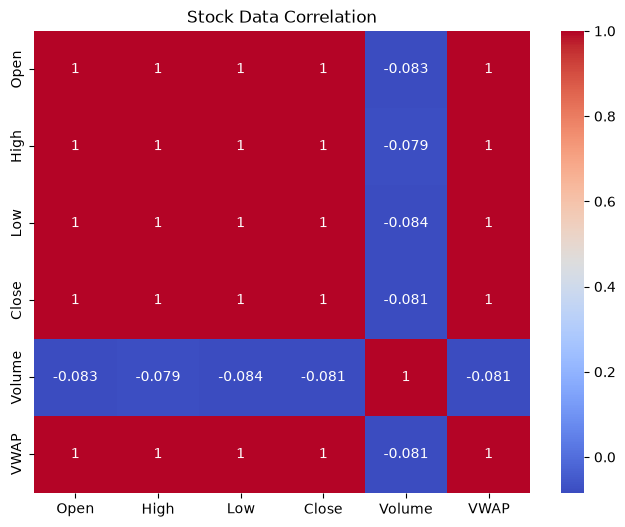

In [14]:
# Select numerical columns for correlation analysis
corr = df[['Open', 'High', 'Low', 'Close', 'Volume', 'VWAP']].corr()

# Set heatmap size
plt.figure(figsize=(8, 6))

# Create correlation heatmap
sns.heatmap(corr, annot=True, cmap='coolwarm')

# Add graph title
plt.title('Stock Data Correlation')

# Display heatmap
plt.show()

11. Stock price forecasting using ARIMA

In [27]:
# Import ARIMA model from statsmodels
from statsmodels.tsa.arima.model import ARIMA

# Select the last 500 closing price records
stock_data = df['Close'].tail(500)

# Create ARIMA model with parameters (5, 1, 0)
model = ARIMA(stock_data, order=(5, 1, 0))

# Train the ARIMA model
model_fit = model.fit()

# Forecast the next 10 stock prices
forecast = model_fit.forecast(steps=10)

# Display predicted prices
print("Next 10 predicted closing prices:")
print(forecast)

Next 10 predicted closing prices:
5306    909.267914
5307    909.289848
5308    909.379055
5309    909.267314
5310    909.368392
5311    909.337221
5312    909.334711
5313    909.341205
5314    909.337483
5315    909.339966
Name: predicted_mean, dtype: float64


12. Plot forecasted stock prices

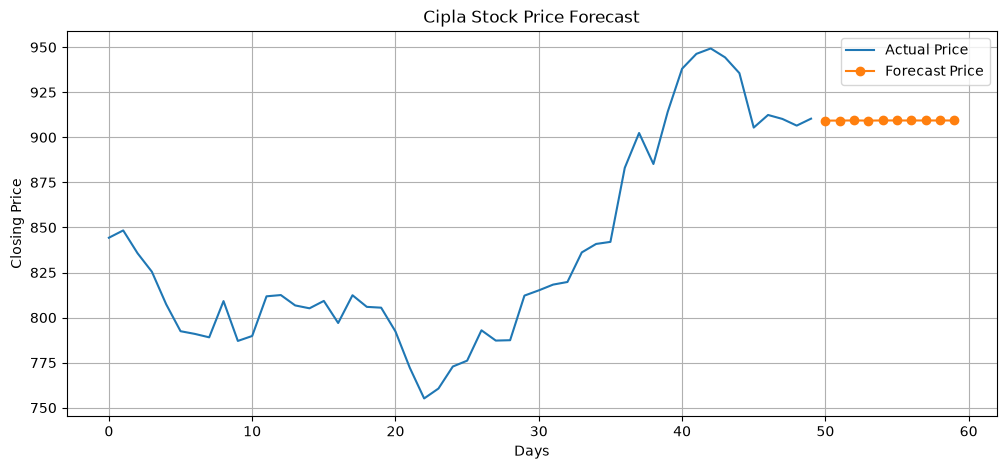

: 

In [ ]:
# Set graph size
plt.figure(figsize=(12, 5))

# Plot the last 50 actual stock prices
plt.plot(stock_data.tail(50).values, label='Actual Price')

# Plot the next 10 forecasted prices
plt.plot(range(50, 60), forecast.values,
         label='Forecast Price', marker='o')

# Add title and axis labels
plt.title('Cipla Stock Price Forecast')
plt.xlabel('Days')
plt.ylabel('Closing Price')

# Display legend and grid
plt.legend()
plt.grid()

# Show graph
plt.show()

13. Display final results

In [19]:
# Display stock market analysis report
print("Stock Market Analysis Report")

# Display company name
print("Company:", df['Symbol'].iloc[0])

# Display total number of records
print("Total Records:", len(df))

# Calculate average closing price
print("Average Closing Price:", df['Close'].mean())

# Find maximum closing price
print("Maximum Closing Price:", df['Close'].max())

# Find minimum closing price
print("Minimum Closing Price:", df['Close'].min())

# Calculate total trading volume
print("Total Trading Volume:", df['Volume'].sum())

Stock Market Analysis Report
Company: CIPLA
Total Records: 5306
Average Closing Price: 540.4210516396531
Maximum Closing Price: 1465.25
Minimum Closing Price: 160.1
Total Trading Volume: 8224676844


14. Save cleaned dataset

In [24]:
# Save cleaned data into a new CSV file
df.to_csv("CIPLA_Cleaned.csv", index=False)

# Display confirmation message
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
